# Ước tính khối lượng hóa chất bị giấu (CBI) – CDR 2024
**Đề tài:** *Filling the confidentiality gap: ML imputation of withheld chemical production volumes with aggregate-constrained reconciliation.*

**Quy trình:**
1. Dựng bảng dữ liệu cấp cơ sở và kiểm tra ràng buộc tổng toàn quốc.
2. Chẩn đoán độ lệch phân phối giữa dòng công khai và dòng CBI, chạy các mốc so sánh và LightGBM.
3. Tăng cường bằng mặt nạ CBI thực nghiệm, kiểm định khi dòng kiểm tra bị giấu kiểu CBI, và tính khoảng dự đoán CQR.
4. Xác định đặc trưng gây lệch phân phối.
5. Kiểm định để riêng từng công ty, và mô phỏng giấu số liệu theo công ty kết hợp hiệu chỉnh theo tổng toàn quốc.
6. Áp dụng cho các dòng CBI thật; tổng hợp cho PFAS và các chất ưu tiên cao của TSCA.
7. Vẽ hình.

**Yêu cầu:** Python ≥ 3.10, cùng các gói `pandas numpy lightgbm scikit-learn scipy pyarrow matplotlib`. Thời gian chạy khoảng 10–15 phút trên CPU.

In [1]:
# !pip install pandas numpy lightgbm scikit-learn scipy pyarrow matplotlib

## 0. Cấu hình đường dẫn
`DATA_DIR` là thư mục chứa 4 file CSV CDR 2024 đã giải nén. `PFAS_FILE` là file phân loại PFAS từ bước pilot; file này không bắt buộc, nếu không có thì phần tổng hợp PFAS sẽ được bỏ qua.

In [2]:
import os, sys, json, re, warnings
warnings.filterwarnings('ignore')
DATA_DIR  = './data'                       # <-- sửa đường dẫn tới thư mục CSV
OUT       = '.'                            # thư mục lưu kết quả
PFAS_FILE = '../pfas_pilot/fluorinated_chemicals_classified.csv'
os.makedirs(OUT, exist_ok=True)
print(sorted(os.listdir(DATA_DIR)))

['2024 CDR Consumer and Commercial Use Information.csv', '2024 CDR Industrial Processing and Use Information.csv', '2024 CDR Manufacture-Import Information.csv', '2024 CDR Nationally Aggregated Production Volumes.csv', '2024 CDR Public Database Dictionary.pdf']


## 1. Dựng bảng dữ liệu cấp cơ sở
Ghép 3 file chi tiết theo cặp (hóa chất, cơ sở), rồi ghép thêm khoảng khối lượng toàn quốc.
**Kiểm tra:** với các hóa chất mà mọi cơ sở đều công khai, tổng khối lượng các cơ sở phải nằm trong khoảng toàn quốc.

In [3]:
import pandas as pd, numpy as np, re, sys
D = DATA_DIR
R = lambda f: pd.read_csv(f'{D}/2024 CDR {f}.csv', encoding='latin1', low_memory=False)
m, i, c, n = R('Manufacture-Import Information'), R('Industrial Processing and Use Information'), R('Consumer and Commercial Use Information'), R('Nationally Aggregated Production Volumes')
num = lambda s: pd.to_numeric(s.astype(str).str.replace(',', ''), errors='coerce')
def rng(s):
    s = str(s); v = [float(x.replace(',', '')) for x in re.findall(r'[\d,]+(?:\.\d+)?', s) if x.replace(',', '')]
    if not v: return (np.nan, np.nan)
    if s.strip().startswith('<'): return (0.0, v[0])
    return (v[0], v[-1])
key = ['CHEMICAL ID', 'EPA-TSCA PROGRAM ID']
m['row_id'] = np.arange(len(m))
m['pv'] = num(m['2023 PV'])
m['status'] = np.where(m['pv'].notna(), 'public', np.where(m['2023 PV'].astype(str) == 'CBI', 'CBI', 'other'))
# national ranges
n['nat_lo'], n['nat_hi'] = zip(*n['2023 NATIONALLY AGGREGATED PV'].map(rng))
nat = n.drop_duplicates('CHEMICAL ID').set_index('CHEMICAL ID')[['nat_lo', 'nat_hi', 'CHEMICAL ID TYPE']]
X = m[key + ['row_id', 'status', 'pv']].copy()
cat_src = {'activity': 'ACTIVITY', 'state': 'SITE STATE', 'workers': 'WORKERS CODE', 'maxconc': 'MAX CONC CODE', 'byp': 'PCT BYP CODE',
           'recycled': 'RECYCLED OR OTHERWISE USED', 'never_at_site': 'CHEM NEVER AT SITE', 'foreign_cc': 'FOREIGN PC COUNTRY CODE', 'phys_form': 'PHYSICAL FORM(S) LIST'}
for k, v in cat_src.items(): X[k] = m[v].astype(str)
X['naics6'] = m['SITE NAICS CODE 1'].astype(str).str[:6]; X['naics3'] = X['naics6'].str[:3]
X['parent'] = m['STANDARDIZED PARENT COMPANY NAME'].astype(str)
X['id_type'] = m['CHEMICAL ID TYPE'].astype(str)
X['n_cbi_fields'] = (m.astype(str) == 'CBI').sum(axis=1)
for k, v in {'onsite': '2023 V USED ON-SITE', 'exported': '2023 V EXPORTED'}.items():
    X['log_' + k] = np.log10(num(m[v]) + 1); X[k + '_cbi'] = (m[v].astype(str) == 'CBI').astype(int)
X = X.join(nat[['nat_lo', 'nat_hi']], on='CHEMICAL ID')
X['nat_log_lo'] = np.log10(X.nat_lo + 1); X['nat_log_hi'] = np.log10(X.nat_hi + 1)
X['n_sites_chem'] = X.groupby('CHEMICAL ID').row_id.transform('count')
X['nat_log_per_site'] = np.log10((np.sqrt(np.maximum(X.nat_lo, 1) * X.nat_hi)) / X.n_sites_chem + 1)
X['n_chem_site'] = X.groupby('EPA-TSCA PROGRAM ID').row_id.transform('count')
X['n_rows_parent'] = X.groupby('parent').row_id.transform('count')
X['frac_cbi_chem_others'] = X.groupby('CHEMICAL ID').status.transform(lambda s: (s == 'CBI').mean())
ind = i.groupby(key).agg(n_ind=('IND FC CODE', 'count'), n_ind_sect=('IND SECT CODE', 'nunique'), ind_fc=('IND FC CODE', 'first'),
                         ind_sect=('IND SECT CODE', 'first'), ind_type=('IND TYPE CODE', 'first'), ind_sites=('IND SITES CODE', 'first'),
                         ind_workers=('IND WORKERS CODE', 'first')).reset_index()
con = c.groupby(key).agg(n_con=('C / C PROD CAT CODE', 'count'), con_cat=('C / C PROD CAT CODE', 'first'), con_use=('CONS AND/OR COMM USE', 'first'),
                         kids=('USED IN PROD FOR CHILDREN', 'first')).reset_index()
X = X.merge(ind, on=key, how='left').merge(con, on=key, how='left')
X[['n_ind', 'n_ind_sect', 'n_con']] = X[['n_ind', 'n_ind_sect', 'n_con']].fillna(0)
X['y'] = np.log10(X.pv.clip(lower=1))
X.to_parquet(OUT + '/site_table.parquet', index=False)
print(X.status.value_counts().to_dict())
print('other rows sample PV values:', m.loc[X.status == 'other', '2023 PV'].astype(str).value_counts().head(3).to_dict())
# sanity: chemicals whose every site is public -> sum vs national range
g = X.groupby('CHEMICAL ID').agg(allpub=('status', lambda s: (s == 'public').all()), s=('pv', 'sum'), lo=('nat_lo', 'first'), hi=('nat_hi', 'first'))
a = g[g.allpub & g.hi.notna()]
print('chems all-public:', len(a), ' sum within national range:', round(((a.s >= a.lo * 0.999) & (a.s <= a.hi * 1.001)).mean(), 3))
cb = X[X.status == 'CBI']
print('CBI rows whose chemical has >=1 public site:', round(cb['CHEMICAL ID'].isin(X.loc[X.status == 'public', 'CHEMICAL ID']).mean(), 3))


{'public': 21838, 'CBI': 21624, 'other': 6971}
other rows sample PV values: {}


chems all-public: 1387  sum within national range: 0.998
CBI rows whose chemical has >=1 public site: 0.736


## 2. Chẩn đoán độ lệch phân phối, mốc so sánh và LightGBM
- *Adversarial validation*: huấn luyện một bộ phân loại để phân biệt dòng CBI với dòng công khai. AUC càng gần 1 thì hai loại dòng càng khác nhau.
- Ba phương pháp: trung vị toàn bộ, chia đều khối lượng toàn quốc cho các cơ sở, và LightGBM.
- Hai cách kiểm định chéo: theo hóa chất chưa thấy, và chia dòng ngẫu nhiên.

In [4]:
import pandas as pd, numpy as np, sys, json, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, KFold, StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
X = pd.read_parquet(OUT + '/site_table.parquet')
CAT = ['activity','state','workers','maxconc','byp','recycled','never_at_site','foreign_cc','phys_form','naics6','naics3','id_type',
       'ind_fc','ind_sect','ind_type','ind_sites','ind_workers','con_cat','con_use','kids']
NUM = ['n_cbi_fields','log_onsite','onsite_cbi','log_exported','exported_cbi','nat_log_lo','nat_log_hi','nat_log_per_site','n_sites_chem',
       'n_chem_site','n_rows_parent','frac_cbi_chem_others','n_ind','n_ind_sect','n_con']
FEAT = CAT + NUM
for c in CAT: X[c] = X[c].astype(object).fillna('NA').astype(str).astype('category')
X = X[X.status.isin(['public','CBI'])].reset_index(drop=True)
P = dict(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=20, subsample=0.8, subsample_freq=1,
         colsample_bytree=0.8, cat_smooth=20, verbose=-1)
res = {}
# 1) adversarial validation: CBI vs public
isc = (X.status == 'CBI').astype(int).values
oof = np.zeros(len(X)); imp = 0
FEAT_ADV = [f for f in FEAT if f not in ('n_cbi_fields','frac_cbi_chem_others')]  # avoid trivially encoding CBI status
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, isc):
    mdl = lgb.LGBMClassifier(**{**P, 'n_estimators': 300}).fit(X.loc[tr, FEAT_ADV], isc[tr])
    oof[te] = mdl.predict_proba(X.loc[te, FEAT_ADV])[:, 1]; imp = imp + mdl.booster_.feature_importance('gain')
res['adversarial_auc'] = roc_auc_score(isc, oof)
res['adversarial_top_features'] = pd.Series(imp, FEAT_ADV).sort_values(ascending=False).head(8).round(0).to_dict()
X['p_cbi'] = oof
# 2) regression on public rows
D = X[X.status == 'public'].reset_index(drop=True); y = D.y.values
BINS = [0, np.log10(25e3), 5, 6, 7, 8, 99]
b = lambda v: np.digitize(v, BINS[1:-1])
def metrics(yt, yp):
    return dict(MAE=float(np.mean(abs(yt - yp))), RMSE=float(np.sqrt(np.mean((yt - yp) ** 2))), bin_acc=float(np.mean(b(yt) == b(yp))),
                within1=float(np.mean(abs(b(yt) - b(yp)) <= 1)), spearman=float(spearmanr(yt, yp)[0]))
schemes = {'unseen_chemical': GroupKFold(5).split(D, y, D['CHEMICAL ID']), 'random_rows': KFold(5, shuffle=True, random_state=0).split(D)}
preds = {}
for sname, split in schemes.items():
    pr = {'global_median': np.zeros(len(D)), 'equal_split': D.nat_log_per_site.values, 'lightgbm': np.zeros(len(D))}
    for tr, te in split:
        pr['global_median'][te] = np.median(y[tr])
        mdl = lgb.LGBMRegressor(**P).fit(D.loc[tr, FEAT], y[tr]); pr['lightgbm'][te] = mdl.predict(D.loc[te, FEAT])
    res[sname] = {k: metrics(y, v) for k, v in pr.items()}
    # performance on CBI-like public rows (top 20% p_cbi)
    hi = D.p_cbi >= D.p_cbi.quantile(0.8)
    res[sname + '_CBIlike_top20pct'] = {k: metrics(y[hi], v[hi]) for k, v in pr.items()}
    preds[sname] = pr['lightgbm']
D['pred_unseen'] = preds['unseen_chemical']; D['pred_random'] = preds['random_rows']
D.to_parquet(OUT + '/public_oof.parquet', index=False); X[['row_id', 'p_cbi']].to_parquet(OUT + '/p_cbi.parquet', index=False)
full = lgb.LGBMRegressor(**P).fit(D[FEAT], y)
res['final_importance_gain'] = pd.Series(full.booster_.feature_importance('gain'), FEAT).sort_values(ascending=False).head(12).round(0).to_dict()
json.dump(res, open(OUT + '/results_model.json', 'w'), indent=1)
for k, v in res.items():
    print('==', k)
    print(pd.DataFrame(v).T.round(3).to_string() if isinstance(v, dict) and isinstance(next(iter(v.values())), dict) else v)


== adversarial_auc
0.9978710102443727
== adversarial_top_features
{'naics6': 624581.0, 'activity': 451222.0, 'n_rows_parent': 440919.0, 'exported_cbi': 297563.0, 'n_chem_site': 203319.0, 'state': 152041.0, 'foreign_cc': 139372.0, 'onsite_cbi': 118396.0}
== unseen_chemical
                 MAE   RMSE  bin_acc  within1  spearman
global_median  1.272  1.688    0.273    0.637    -0.051
equal_split      NaN    NaN    0.424    0.746       NaN
lightgbm       0.476  0.705    0.593    0.945     0.856
== unseen_chemical_CBIlike_top20pct
                 MAE   RMSE  bin_acc  within1  spearman
global_median  1.268  1.643    0.265    0.623    -0.018
equal_split      NaN    NaN    0.406    0.729       NaN
lightgbm       0.579  0.816    0.528    0.924     0.847
== random_rows
                 MAE   RMSE  bin_acc  within1  spearman
global_median  1.271  1.687    0.273    0.637    -0.007
equal_split      NaN    NaN    0.424    0.746       NaN
lightgbm       0.451  0.681    0.610    0.948     0.860
== r

## 3. Tăng cường bằng mặt nạ CBI và tính khoảng dự đoán CQR
### 3a. Hàm dùng chung
Các mặt nạ được lấy mẫu từ **đúng tổ hợp các trường bị giấu** trên dòng CBI thật, rồi áp lên dòng công khai.

In [5]:
import pandas as pd, numpy as np, sys, json, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr
rng = np.random.default_rng(0)
X = pd.read_parquet(OUT + '/site_table.parquet'); X = X[X.status.isin(['public', 'CBI'])].reset_index(drop=True)
raw_site_cbi = X['EPA-TSCA PROGRAM ID'].astype(str) == 'CBI'; raw_parent_cbi = X['parent'].astype(str) == 'CBI'
X.loc[raw_site_cbi, 'n_chem_site'] = np.nan; X.loc[raw_parent_cbi, 'n_rows_parent'] = np.nan
X['nat_log_per_site'] = X['nat_log_per_site'].fillna(X['nat_log_per_site'].median())
CAT = ['activity','state','workers','maxconc','byp','recycled','never_at_site','foreign_cc','phys_form','naics6','naics3','id_type',
       'ind_fc','ind_sect','ind_type','ind_sites','ind_workers','con_cat','con_use','kids']
NUM = ['log_onsite','log_exported','nat_log_lo','nat_log_hi','nat_log_per_site','n_sites_chem','n_chem_site','n_rows_parent',
       'frac_cbi_chem_others','n_ind','n_ind_sect','n_con']
FEAT = CAT + NUM
# mask groups: name -> (indicator from raw, columns affected)
MG = {'site': (raw_site_cbi | (X.state.astype(str) == 'CBI'), ['state','naics6','naics3','n_chem_site']),
      'parent': (raw_parent_cbi | (X.foreign_cc.astype(str) == 'CBI'), ['foreign_cc','n_rows_parent']),
      'activity': (X.activity.astype(str) == 'CBI', ['activity']), 'workers': (X.workers.astype(str) == 'CBI', ['workers']),
      'maxconc': (X.maxconc.astype(str) == 'CBI', ['maxconc']), 'byp': (X.byp.astype(str) == 'CBI', ['byp']),
      'recycled': (X.recycled.astype(str) == 'CBI', ['recycled']), 'phys_form': (X.phys_form.astype(str) == 'CBI', ['phys_form']),
      'onsite': (X.onsite_cbi == 1, ['log_onsite']), 'exported': (X.exported_cbi == 1, ['log_exported'])}
M = pd.DataFrame({k: v[0].values for k, v in MG.items()})
cbi_patterns = M[X.status.values == 'CBI'].values
def apply_mask(df, pats):
    df = df.copy()
    for j, (k, (_, cols)) in enumerate(MG.items()):
        sel = pats[:, j]
        for c in cols:
            if c in CAT: df[c] = df[c].astype(object); df.loc[sel, c] = 'CBI'
            else: df.loc[sel, c] = np.nan
    return df
def sample_masks(n): return cbi_patterns[rng.integers(0, len(cbi_patterns), n)]
def prep(df):
    df = df.copy()
    for c in CAT: df[c] = pd.Categorical(df[c].astype(object).fillna('NA').astype(str), categories=CATS[c])
    return df
CATS = {c: sorted(set(X[c].astype(object).fillna('NA').astype(str)) | {'CBI'}) for c in CAT}
P = dict(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=20, subsample=0.8, subsample_freq=1,
         colsample_bytree=0.8, cat_smooth=20, verbose=-1)
BINS = [np.log10(25e3), 5, 6, 7, 8]; b = lambda v: np.digitize(v, BINS)
def metrics(yt, yp): return dict(MAE=float(np.mean(abs(yt-yp))), RMSE=float(np.sqrt(np.mean((yt-yp)**2))), bin_acc=float(np.mean(b(yt)==b(yp))),
                                 within1=float(np.mean(abs(b(yt)-b(yp))<=1)), spearman=float(spearmanr(yt, yp)[0]))
def augment(df, k=2):
    return pd.concat([df] + [apply_mask(df, sample_masks(len(df))) for _ in range(k)], ignore_index=True)


### 3b. Kiểm định khi dòng kiểm tra bị giấu kiểu CBI, và CQR 90% (có bản có trọng số theo độ lệch)

In [6]:
D = X[X.status == 'public'].reset_index(drop=True); y = D.y.values
res = {}
# residual shift after harmonizing masks
Dm = apply_mask(D, sample_masks(len(D))); C = X[X.status == 'CBI']
A = prep(pd.concat([Dm[FEAT], C[FEAT]], ignore_index=True)); lab = np.r_[np.zeros(len(Dm)), np.ones(len(C))]
oof = np.zeros(len(A))
FA = [f for f in FEAT if f != 'frac_cbi_chem_others']
for tr, te in StratifiedKFold(5, shuffle=True, random_state=1).split(A, lab):
    oof[te] = lgb.LGBMClassifier(**{**P, 'n_estimators': 300}).fit(A.iloc[tr][FA], lab[tr]).predict_proba(A.iloc[te][FA])[:, 1]
res['adversarial_auc_after_mask_harmonization'] = float(roc_auc_score(lab, oof))
pc = np.clip(oof[:len(Dm)], 0.01, 0.99); w_pub = pc / (1 - pc)   # density-ratio weights for public rows
# CV: unseen chemicals, test rows masked with empirical CBI patterns
out = {k: np.zeros(len(D)) for k in ['clean_model', 'augmented_model', 'equal_split', 'q05', 'q95']}
test_masked = np.zeros(len(D), bool)
gkf = list(GroupKFold(5).split(D, y, D['CHEMICAL ID']))
for f, (tr, te) in enumerate(gkf):
    Te = prep(apply_mask(D.loc[te], sample_masks(len(te))))
    m0 = lgb.LGBMRegressor(**P).fit(prep(D.loc[tr])[FEAT], y[tr]); out['clean_model'][te] = m0.predict(Te[FEAT])
    Tr = augment(D.loc[tr]); yt = np.tile(y[tr], 3)
    m1 = lgb.LGBMRegressor(**P).fit(prep(Tr)[FEAT], yt); out['augmented_model'][te] = m1.predict(Te[FEAT])
    for q, nm in [(0.05, 'q05'), (0.95, 'q95')]:
        out[nm][te] = lgb.LGBMRegressor(**{**P, 'objective': 'quantile', 'alpha': q}).fit(prep(Tr)[FEAT], yt).predict(Te[FEAT])
    out['equal_split'][te] = D.loc[te, 'nat_log_per_site'].values
res['simulated_CBI_test_unseen_chemical'] = {k: metrics(y, out[k]) for k in ['equal_split', 'clean_model', 'augmented_model']}
# CQR: calibrate on half of chemicals, evaluate on other half (repeat 20 splits)
chem = D['CHEMICAL ID'].values; uc = np.unique(chem)
s = np.maximum(out['q05'] - y, y - out['q95'])
cov, covw, wid, widw, cov_hi, covw_hi = [], [], [], [], [], []
hi = pc >= np.quantile(pc, 0.8)
for r in range(20):
    cal = np.isin(chem, rng.choice(uc, len(uc) // 2, replace=False)); ev = ~cal
    qh = np.quantile(s[cal], np.ceil((cal.sum() + 1) * 0.9) / cal.sum())
    # weighted conformal (Tibshirani et al. 2019): weighted quantile of calibration scores
    o = np.argsort(s[cal]); sw = s[cal][o]; ww = w_pub[cal][o]; cw = np.cumsum(ww) / (ww.sum() + np.median(w_pub[ev]))
    qw = sw[np.searchsorted(cw, 0.9)] if (cw >= 0.9).any() else np.inf
    lo, up = out['q05'] - qh, out['q95'] + qh; low, upw = out['q05'] - qw, out['q95'] + qw
    inn = (y >= lo) & (y <= up); innw = (y >= low) & (y <= upw)
    cov.append(inn[ev].mean()); covw.append(np.average(innw[ev], weights=w_pub[ev])); wid.append((up - lo)[ev].mean()); widw.append((upw - low)[ev].mean())
    cov_hi.append(inn[ev & hi].mean()); covw_hi.append(innw[ev & hi].mean())
res['conformal_90'] = dict(raw_quantile_coverage=float(np.mean((y >= out['q05']) & (y <= out['q95']))),
    CQR_coverage=float(np.mean(cov)), CQR_mean_width_log10=float(np.mean(wid)), CQR_coverage_CBIlike_top20=float(np.mean(cov_hi)),
    weightedCQR_coverage_shift_weighted=float(np.mean(covw)), weightedCQR_mean_width_log10=float(np.mean(widw)), weightedCQR_coverage_CBIlike_top20=float(np.mean(covw_hi)))
res['simulated_CBI_test_CBIlike_top20'] = {k: metrics(y[hi], out[k][hi]) for k in ['equal_split', 'clean_model', 'augmented_model']}
D['oof_aug'] = out['augmented_model']; D['oof_q05'] = out['q05']; D['oof_q95'] = out['q95']; D['w_shift'] = w_pub
D.to_parquet(OUT + '/public_oof_masked.parquet', index=False)
json.dump(res, open(OUT + '/results_mask_aug.json', 'w'), indent=1)
for k, v in res.items():
    print('==', k); print(pd.DataFrame(v).T.round(3).to_string() if isinstance(v, dict) and isinstance(next(iter(v.values())), dict) else v)


== adversarial_auc_after_mask_harmonization
0.9943270178427182
== simulated_CBI_test_unseen_chemical
                   MAE   RMSE  bin_acc  within1  spearman
equal_split      1.011  1.452    0.426    0.752     0.638
clean_model      0.571  0.822    0.526    0.917     0.816
augmented_model  0.547  0.787    0.541    0.929     0.825
== conformal_90
{'raw_quantile_coverage': 0.8259455994138657, 'CQR_coverage': 0.9004906575913132, 'CQR_mean_width_log10': 2.5249757052499575, 'CQR_coverage_CBIlike_top20': 0.8710694364031542, 'weightedCQR_coverage_shift_weighted': 0.8974858762461919, 'weightedCQR_mean_width_log10': 2.6172370360585573, 'weightedCQR_coverage_CBIlike_top20': 0.8885556471451908}
== simulated_CBI_test_CBIlike_top20
                   MAE   RMSE  bin_acc  within1  spearman
equal_split      1.034  1.479    0.424    0.748     0.625
clean_model      0.650  0.899    0.482    0.898     0.821
augmented_model  0.628  0.875    0.487    0.907     0.824


## 4. Đặc trưng nào gây lệch phân phối?
Tính AUC của bộ phân loại khi chỉ dùng từng đặc trưng một.

In [7]:
import pandas as pd, numpy as np, sys, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
D = X[X.status == 'public'].reset_index(drop=True); C = X[X.status == 'CBI']
Dm = apply_mask(D, sample_masks(len(D)))
A = prep(pd.concat([Dm[FEAT], C[FEAT]], ignore_index=True)); lab = np.r_[np.zeros(len(Dm)), np.ones(len(C))]
def auc(cols):
    oof = np.zeros(len(A))
    for tr, te in StratifiedKFold(3, shuffle=True, random_state=1).split(A, lab):
        oof[te] = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31, verbose=-1).fit(A.iloc[tr][cols], lab[tr]).predict_proba(A.iloc[te][cols])[:, 1]
    return roc_auc_score(lab, oof)
FA = [f for f in FEAT if f != 'frac_cbi_chem_others']
print('all', round(auc(FA), 3))
for f in FA: print(f'single {f:22s}', round(auc([f]), 3))


all 0.992


single activity               0.59


single state                  0.62


single workers                0.576


single maxconc                0.573


single byp                    0.606


... (22 outputs left out)

single n_rows_parent          0.854


single n_ind                  0.607


single n_ind_sect             0.582


single n_con                  0.645


## 5. Kiểm định để riêng từng công ty, và mô phỏng giấu theo công ty kèm hiệu chỉnh
- Chọn ngẫu nhiên 20% số công ty, xác suất được chọn tăng theo quy mô công ty, và coi như các công ty này giấu toàn bộ số liệu.
- Chỉ dùng các hóa chất không có dòng CBI thật, để biết chính xác đáp án.
- Hiệu chỉnh bằng cách co giãn dự đoán để phần khối lượng thuộc dòng bị giấu khớp với (khoảng toàn quốc − tổng các dòng công khai).

In [8]:
import pandas as pd, numpy as np, sys, json, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
D = X[X.status == 'public'].reset_index(drop=True); y = D.y.values
res = {}
def fit(df, yy, **kw): return lgb.LGBMRegressor(**{**P, **kw}).fit(prep(df)[FEAT], yy)
# (a) leave-company-out
pred = np.zeros(len(D))
for tr, te in GroupKFold(5).split(D, y, D.parent.astype(str)):
    m = fit(augment(D.loc[tr]), np.tile(y[tr], 3)); pred[te] = m.predict(prep(apply_mask(D.loc[te], sample_masks(len(te))))[FEAT])
res['leave_company_out'] = {**metrics(y, pred), 'bias_log10': float(np.mean(pred - y))}
big = D.n_rows_parent >= D.n_rows_parent.quantile(0.9)
res['leave_company_out_large_companies'] = {**metrics(y[big], pred[big]), 'bias_log10': float(np.mean(pred[big] - y[big]))}
# (b) pseudo-CBI simulation on chemicals with no real CBI rows (national range == sum of public sites)
allpub = X.groupby('CHEMICAL ID').status.apply(lambda s: (s == 'public').all())
chem_ok = set(allpub[allpub].index)
def reconcile(df, pcol, known, lo, hi):
    """Scale pseudo-CBI predictions (linear space) of each chemical so that known + sum(pred) lies in [lo, hi]."""
    df = df.copy(); df['lin'] = 10 ** df[pcol]
    tot = df.groupby('CHEMICAL ID').lin.transform('sum')
    rlo = (df['CHEMICAL ID'].map(lo) - df['CHEMICAL ID'].map(known)).clip(lower=0)
    rhi = (df['CHEMICAL ID'].map(hi) - df['CHEMICAL ID'].map(known)).clip(lower=1)
    f = np.where(tot < rlo, rlo / tot, np.where(tot > rhi, rhi / tot, 1.0))
    return np.log10(np.clip(df.lin * f, 1, None)), float(np.mean(f != 1))
sims = []
parents = D.parent.astype(str).unique()
for r in range(5):
    rs = np.random.default_rng(100 + r)
    # company-level policy: pick parents at random, probability rising with company size (mimics observed pattern)
    sz = D.groupby(D.parent.astype(str)).size(); pr = (sz ** 0.5) / (sz ** 0.5).sum()
    pick = set(rs.choice(sz.index, size=int(0.2 * len(sz)), replace=False, p=pr.values))
    pseudo = D.parent.astype(str).isin(pick).values & D['CHEMICAL ID'].isin(chem_ok).values
    tr = ~D.parent.astype(str).isin(pick).values
    m = fit(augment(D[tr]), np.tile(y[tr], 3))
    T = D[pseudo].copy(); T['pred'] = m.predict(prep(apply_mask(T, sample_masks(len(T))))[FEAT])
    known = D[~pseudo].groupby('CHEMICAL ID').pv.sum()
    nlo = D.groupby('CHEMICAL ID').nat_lo.first(); nhi = D.groupby('CHEMICAL ID').nat_hi.first()
    T['pred_rec'], frac_adj = reconcile(T, 'pred', known.reindex(nlo.index).fillna(0), nlo, nhi)
    # chemical-level totals error (log10 of hidden total)
    ct = T.groupby('CHEMICAL ID').agg(true=('pv', 'sum'), p=('pred', lambda v: (10 ** v).sum()), pr=('pred_rec', lambda v: (10 ** v).sum()))
    sims.append(dict(n_pseudo_rows=int(pseudo.sum()), frac_chem_adjusted=frac_adj,
        row_MAE_ml=float(np.mean(abs(T.pred - T.y))), row_MAE_reconciled=float(np.mean(abs(T.pred_rec - T.y))),
        row_bias_ml=float(np.mean(T.pred - T.y)), row_bias_reconciled=float(np.mean(T.pred_rec - T.y)),
        row_within1_ml=float(np.mean(abs(b(T.pred) - b(T.y)) <= 1)), row_within1_reconciled=float(np.mean(abs(b(T.pred_rec) - b(T.y)) <= 1)),
        chem_total_MAE_ml=float(np.mean(abs(np.log10(ct.p) - np.log10(ct.true)))), chem_total_MAE_reconciled=float(np.mean(abs(np.log10(ct.pr) - np.log10(ct.true))))))
S = pd.DataFrame(sims); res['company_pseudoCBI_sim_mean'] = S.mean().to_dict(); res['company_pseudoCBI_sim_sd'] = S.std().to_dict()
json.dump(res, open(OUT + '/results_company_sim.json', 'w'), indent=1)
print(json.dumps(res, indent=1))


{
 "leave_company_out": {
  "MAE": 0.640495703402393,
  "RMSE": 0.9046221951189558,
  "bin_acc": 0.47930213389504533,
  "within1": 0.8625789907500687,
  "spearman": 0.745077142194976,
  "bias_log10": -0.07871953275560324
 },
 "leave_company_out_large_companies": {
  "MAE": 0.9823441521202575,
  "RMSE": 1.1909411462151482,
  "bin_acc": 0.1797752808988764,
  "within1": 0.5509492444788842,
  "spearman": 0.06476230758716725,
  "bias_log10": -0.5931914442300921
 },
 "company_pseudoCBI_sim_mean": {
  "n_pseudo_rows": 1540.2,
  "frac_chem_adjusted": 0.9575279043420828,
  "row_MAE_ml": 0.5380654847859623,
  "row_MAE_reconciled": 0.32143151659163993,
  "row_bias_ml": -0.23176824747001318,
  "row_bias_reconciled": 0.13193005172125075,
  "row_within1_ml": 0.8531072429096097,
  "row_within1_reconciled": 0.9603974585651394,
  "chem_total_MAE_ml": 0.3243932036673652,
  "chem_total_MAE_reconciled": 0.014885525463577862
 },
 "company_pseudoCBI_sim_sd": {
  "n_pseudo_rows": 64.5189894527185,
  "frac_ch

## 6. Áp dụng cho các dòng CBI thật
Gồm dự đoán điểm, khoảng 90% bằng CQR, hiệu chỉnh theo tổng toàn quốc, và tổng hợp cho PFAS cùng 20 chất ưu tiên cao của TSCA.

In [9]:
import pandas as pd, numpy as np, sys, json, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
PF = PFAS_FILE if os.path.exists(PFAS_FILE) else None
D = X[X.status == 'public'].reset_index(drop=True); y = D.y.values
C = X[X.status == 'CBI'].reset_index(drop=True)
Tr = prep(augment(D)); yt = np.tile(y, 3)
mk = lambda **kw: lgb.LGBMRegressor(**{**P, **kw}).fit(Tr[FEAT], yt)
Cp = prep(C)
C['pred'] = mk().predict(Cp[FEAT])
q05 = mk(objective='quantile', alpha=0.05).predict(Cp[FEAT]); q95 = mk(objective='quantile', alpha=0.95).predict(Cp[FEAT])
O = pd.read_parquet(OUT + '/public_oof_masked.parquet')
s = np.maximum(O.oof_q05 - O.y, O.y - O.oof_q95); qh = np.quantile(s, np.ceil((len(s) + 1) * 0.9) / len(s))
C['lo90'], C['hi90'] = np.minimum(q05 - qh, C.pred), np.maximum(q95 + qh, C.pred)
# reconciliation with national range minus public sum
known = D.groupby('CHEMICAL ID').pv.sum()
g = C.groupby('CHEMICAL ID'); tot = g.pred.transform(lambda v: (10 ** v).sum())
nlo, nhi = C['CHEMICAL ID'].map(X.groupby('CHEMICAL ID').nat_lo.first()), C['CHEMICAL ID'].map(X.groupby('CHEMICAL ID').nat_hi.first())
kn = C['CHEMICAL ID'].map(known).fillna(0)
rlo, rhi = (nlo - kn).clip(lower=0), (nhi - kn).clip(lower=1)
f = np.where(nhi.isna(), 1.0, np.where(tot < rlo, rlo / tot, np.where(tot > rhi, rhi / tot, 1.0)))
sh = np.log10(f)
C['pred_rec'] = C.pred + sh; C['lo90_rec'] = C.lo90 + sh; C['hi90_rec'] = C.hi90 + sh; C['rec_factor'] = f
C['pv_hat_lb'] = 10 ** C.pred_rec
C.to_csv(OUT + '/imputed_cbi_rows.csv', index=False)
res = dict(n_cbi_rows=len(C), conformal_margin_log10=float(qh), mean_interval_width_log10=float((C.hi90 - C.lo90).mean()),
           frac_rows_reconciled=float(np.mean(f != 1)), median_reconcile_factor_up=float(np.median(f[f > 1])) if (f > 1).any() else 1.0,
           frac_reconciled_upward=float(np.mean(f > 1)), frac_reconciled_downward=float(np.mean(f < 1)),
           mean_shift_log10=float(np.mean(sh)))
# hidden share of national volume
nat = X.groupby('CHEMICAL ID').agg(lo=('nat_lo', 'first'), hi=('nat_hi', 'first')); nat['pub'] = known.reindex(nat.index).fillna(0)
nat['imp'] = C.groupby('CHEMICAL ID').pv_hat_lb.sum().reindex(nat.index).fillna(0)
nat['hidden_share'] = nat.imp / (nat.imp + nat.pub)
res['volume_weighted_hidden_share_all'] = float(nat.imp.sum() / (nat.imp.sum() + nat.pub.sum()))
res['chemicals_with_any_CBI_row'] = int((nat.imp > 0).sum())
res['chemicals_majority_hidden'] = int((nat.hidden_share > 0.5).sum())
if PF:
    pf = pd.read_csv(PF); ids = set(pf.loc[pf.group.str.startswith('PFAS', na=False), 'id'].astype(str))
    sub = nat[nat.index.astype(str).isin(ids)]
    res['PFAS'] = dict(n_chem=len(sub), hidden_share_volume=float(sub.imp.sum() / max(sub.imp.sum() + sub.pub.sum(), 1)),
                       imputed_Mlb=float(sub.imp.sum() / 1e6), public_Mlb=float(sub.pub.sum() / 1e6))
HP = {'106-46-7':'p-Dichlorobenzene','107-06-2':'1,2-Dichloroethane','156-60-5':'trans-1,2-Dichloroethylene','95-50-1':'o-Dichlorobenzene',
      '79-00-5':'1,1,2-Trichloroethane','78-87-5':'1,2-Dichloropropane','75-34-3':'1,1-Dichloroethane','106-99-0':'1,3-Butadiene',
      '50-00-0':'Formaldehyde','85-44-9':'Phthalic anhydride','79-94-7':'TBBPA','115-96-8':'TCEP','13674-87-8':'TDCPP','1222-05-5':'HHCB',
      '84-74-2':'DBP','85-68-7':'BBP','117-81-7':'DEHP','84-69-5':'DIBP','84-61-7':'DCHP','115-86-6':'Triphenyl phosphate'}
hp = nat.reindex([k for k in HP if k in nat.index]).copy(); hp['name'] = [HP[k] for k in hp.index]
hp['n_sites_public'] = D.groupby('CHEMICAL ID').size().reindex(hp.index).fillna(0).astype(int)
hp['n_sites_cbi'] = C.groupby('CHEMICAL ID').size().reindex(hp.index).fillna(0).astype(int)
hp = hp[['name', 'n_sites_public', 'n_sites_cbi', 'lo', 'hi', 'pub', 'imp', 'hidden_share']]
hp.to_csv(OUT + '/tsca_high_priority_summary.csv'); nat.to_csv(OUT + '/chemical_level_summary.csv')
json.dump(res, open(OUT + '/results_apply.json', 'w'), indent=1)
print(json.dumps(res, indent=1)); print(hp.assign(lo=hp.lo/1e6, hi=hp.hi/1e6, pub=hp.pub/1e6, imp=hp.imp/1e6).round(2).to_string())


{
 "n_cbi_rows": 21624,
 "conformal_margin_log10": 0.10891620429911933,
 "mean_interval_width_log10": 2.667266452175445,
 "frac_rows_reconciled": 0.6280521642619312,
 "median_reconcile_factor_up": 2.9883383911618107,
 "frac_reconciled_upward": 0.6059933407325194,
 "frac_reconciled_downward": 0.022058823529411766,
 "mean_shift_log10": 0.31969473583032365,
 "volume_weighted_hidden_share_all": 0.40491648585096873,
 "chemicals_with_any_CBI_row": 6560,
 "chemicals_majority_hidden": 5087,
 "PFAS": {
  "n_chem": 213,
  "hidden_share_volume": 0.9213693848220371,
  "imputed_Mlb": 753.4631191543639,
  "public_Mlb": 64.301321
 }
}
                                   name  n_sites_public  n_sites_cbi        lo        hi       pub       imp  hidden_share
CHEMICAL ID                                                                                                               
106-46-7              p-Dichlorobenzene               1            2     10.00     50.00      3.60      6.40          0.64
107

## 7. Hình

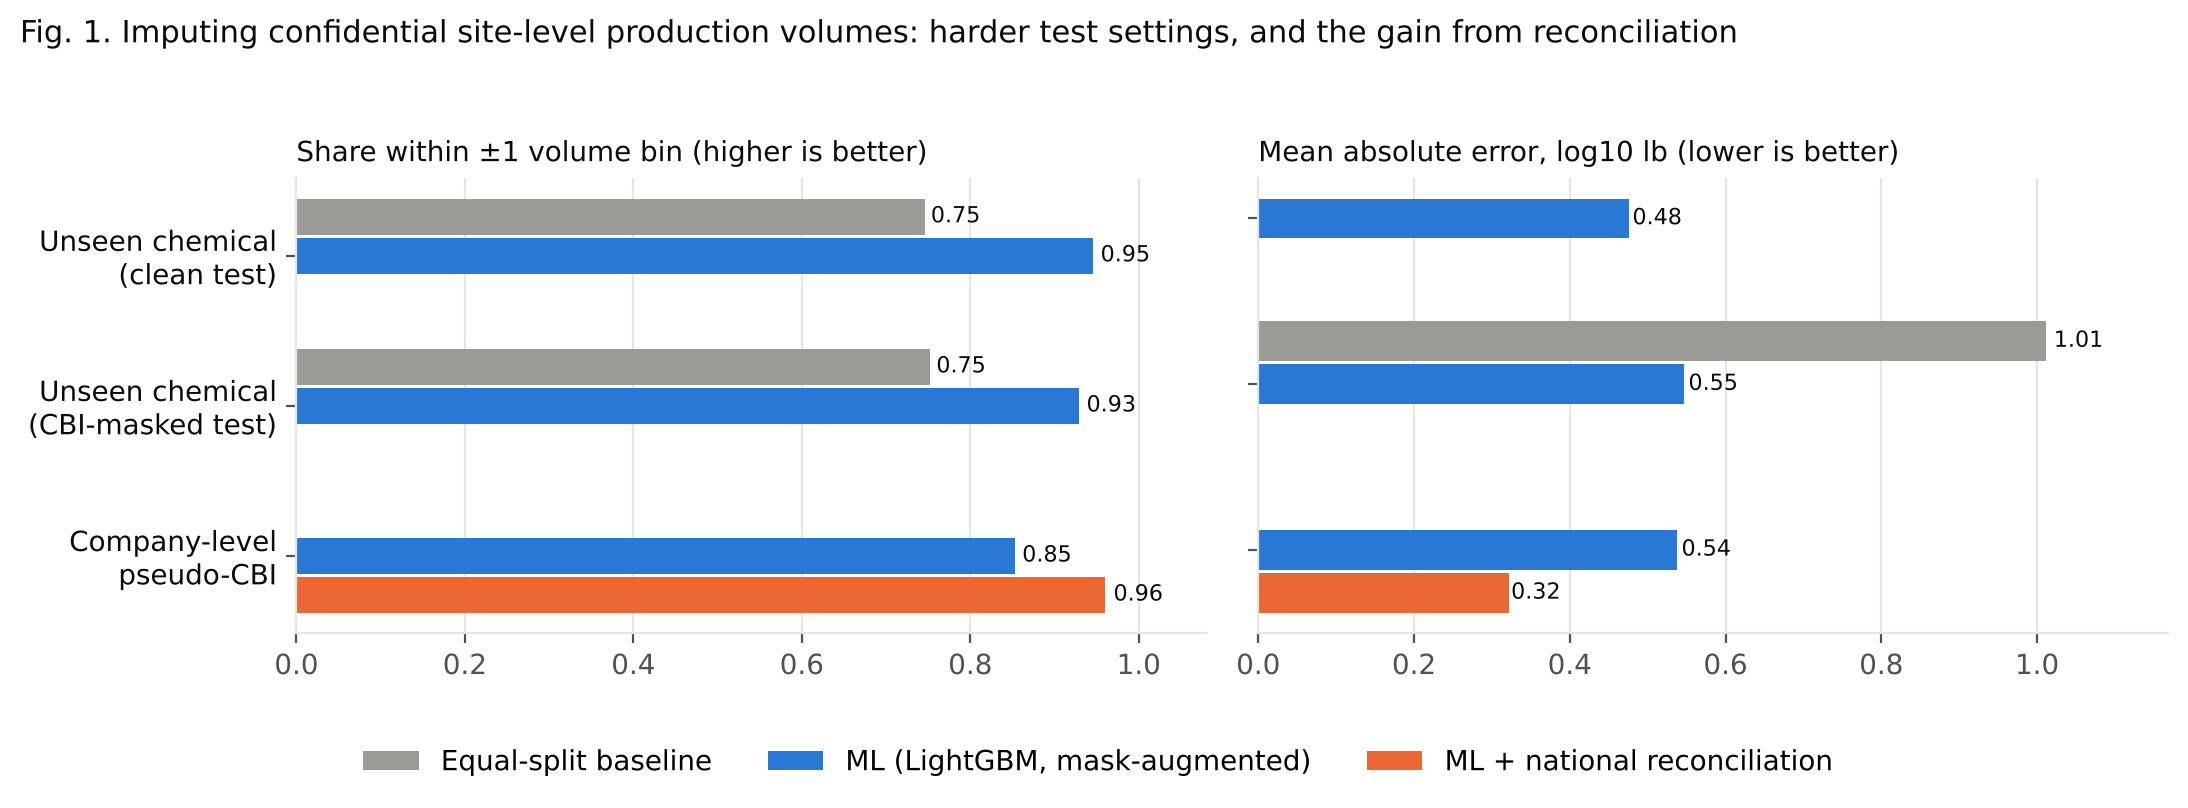

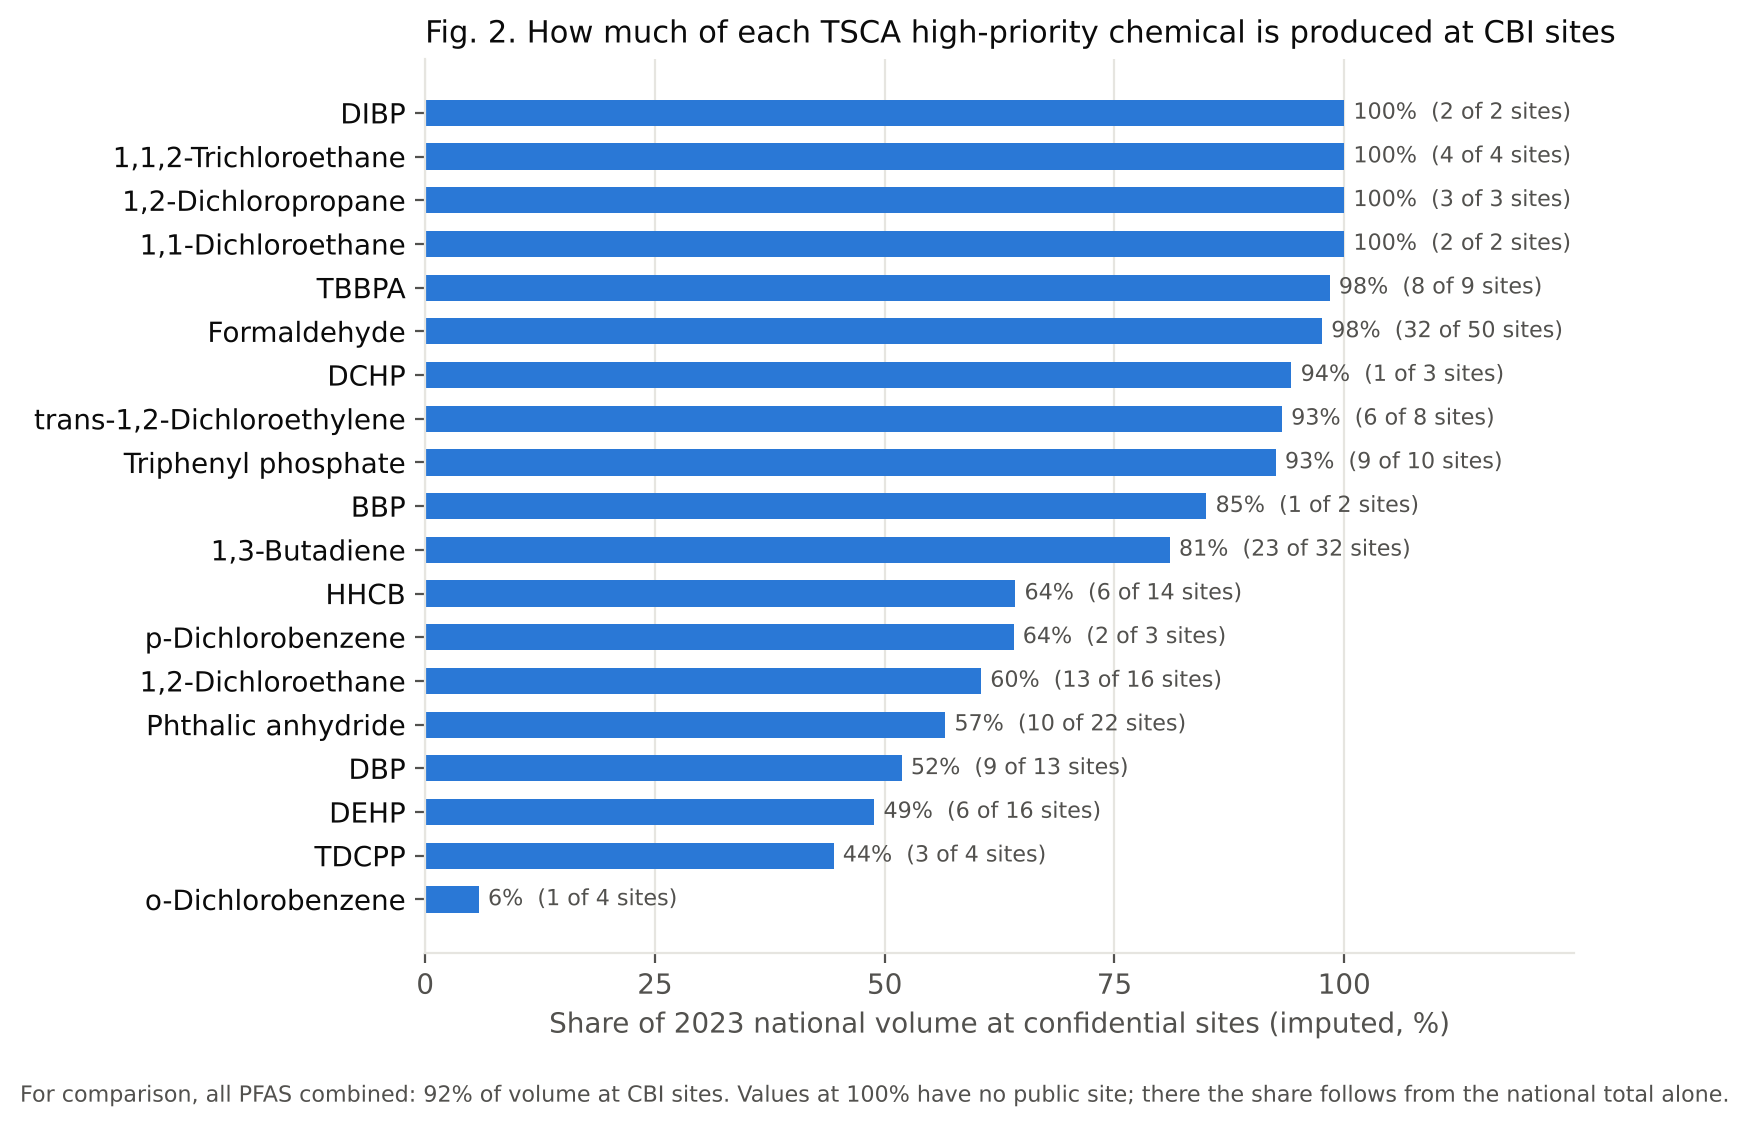

In [10]:
import json, pandas as pd, numpy as np, matplotlib, sys
matplotlib.use('Agg'); import matplotlib.pyplot as plt
r2, r3, r4, r5 = [json.load(open(f'{OUT}/results_{k}.json')) for k in ['model', 'mask_aug', 'company_sim', 'apply']]
BLUE, ORANGE, AQUA, GRAY, TXT, TXT2, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#9b9a95', '#0b0b0b', '#52514e', '#e6e5e0'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID, 'xtick.color': TXT2, 'ytick.color': TXT2,
                     'axes.spines.top': False, 'axes.spines.right': False})
# Fig 1: evaluation ladder
rows = [('Unseen chemical\n(clean test)', r2['unseen_chemical']['equal_split'], r2['unseen_chemical']['lightgbm'], None),
        ('Unseen chemical\n(CBI-masked test)', r3['simulated_CBI_test_unseen_chemical']['equal_split'], r3['simulated_CBI_test_unseen_chemical']['augmented_model'], None),
        ('Company-level\npseudo-CBI', None, {'MAE': r4['company_pseudoCBI_sim_mean']['row_MAE_ml'], 'within1': r4['company_pseudoCBI_sim_mean']['row_within1_ml']},
         {'MAE': r4['company_pseudoCBI_sim_mean']['row_MAE_reconciled'], 'within1': r4['company_pseudoCBI_sim_mean']['row_within1_reconciled']})]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, (met, title) in enumerate([('within1', 'Share within ±1 volume bin (higher is better)'), ('MAE', 'Mean absolute error, log10 lb (lower is better)')]):
    a = ax[k]
    for j, (lab, eq, ml, rec) in enumerate(rows):
        pts = [('Equal-split baseline', eq, GRAY), ('ML (LightGBM, mask-augmented)', ml, BLUE), ('ML + national reconciliation', rec, ORANGE)]
        for o, (nm, d, c) in enumerate(pts):
            if d is None or d.get(met) is None or (isinstance(d.get(met), float) and np.isnan(d.get(met))): continue
            a.barh(j + (o - 1) * 0.26, d[met], height=0.24, color=c, label=nm if (k == 0 and j == 2) or (k == 0 and j == 0 and o == 0) else None)
            a.text(d[met] * 1.01, j + (o - 1) * 0.26, f'{d[met]:.2f}', va='center', fontsize=8, color=TXT)
    a.set_yticks(range(len(rows))); a.set_yticklabels([r[0] for r in rows] if k == 0 else [''] * 3, color=TXT); a.invert_yaxis()
    a.set_title(title, loc='left', fontsize=10, color=TXT); a.xaxis.grid(True, color=GRID); a.set_axisbelow(True)
    a.set_xlim(0, (1.08 if met == 'within1' else max(1.15, a.get_xlim()[1] * 1.1)))
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('Fig. 1. Imputing confidential site-level production volumes: harder test settings, and the gain from reconciliation', x=0.01, ha='left', fontsize=11, color=TXT)
plt.tight_layout(rect=(0, 0.07, 1, 0.94)); plt.savefig(OUT + '/fig1_evaluation.png', dpi=200, bbox_inches='tight'); plt.close()
# Fig 2: hidden share TSCA high-priority
hp = pd.read_csv(OUT + '/tsca_high_priority_summary.csv').sort_values('hidden_share')
fig, a = plt.subplots(figsize=(8, 5.4))
a.barh(range(len(hp)), hp.hidden_share * 100, color=BLUE, height=0.6)
for j, (_, r) in enumerate(hp.iterrows()):
    a.text(r.hidden_share * 100 + 1, j, f"{r.hidden_share*100:.0f}%  ({int(r.n_sites_cbi)} of {int(r.n_sites_cbi + r.n_sites_public)} sites)", va='center', fontsize=8, color=TXT2)
fig.text(0.01, -0.03, f"For comparison, all PFAS combined: {r5['PFAS']['hidden_share_volume']*100:.0f}% of volume at CBI sites. Values at 100% have no public site; there the share follows from the national total alone.", fontsize=8, color=TXT2)
a.set_yticks(range(len(hp))); a.set_yticklabels(hp.name, color=TXT); a.set_xlim(0, 125); a.set_xticks([0, 25, 50, 75, 100])
a.set_xlabel('Share of 2023 national volume at confidential sites (imputed, %)', color=TXT2); a.xaxis.grid(True, color=GRID); a.set_axisbelow(True)
a.set_title('Fig. 2. How much of each TSCA high-priority chemical is produced at CBI sites', loc='left', fontsize=11, color=TXT)
plt.tight_layout(); plt.savefig(OUT + '/fig2_hidden_share_priority.png', dpi=200, bbox_inches='tight')

from IPython.display import Image, display
for f in ['fig1_evaluation.png','fig2_hidden_share_priority.png']: display(Image(os.path.join(OUT, f)))

## 8. Mô phỏng khó: kịch bản A (giấu theo công ty), B (tỷ lệ giấu theo phân bố thực tế), C (khoảng toàn quốc rộng 10 lần)
So sánh 4 phương pháp: chỉ ML; ML + hiệu chỉnh về cận gần nhất (đề xuất); ML + hiệu chỉnh về điểm giữa; chia đều phần còn lại (không dùng ML). Thời gian chạy khoảng 15 phút.

In [11]:
import pandas as pd, numpy as np, sys, json, warnings; warnings.filterwarnings('ignore')
import lightgbm as lgb
from scipy.stats import spearmanr
D = X[X.status == 'public'].reset_index(drop=True); y = D.y.values
allpub = X.groupby('CHEMICAL ID').status.apply(lambda s: (s == 'public').all())
ok = D['CHEMICAL ID'].isin(set(allpub[allpub].index)).values
# empirical per-chemical CBI fraction among chemicals that have CBI rows
fr = X.groupby('CHEMICAL ID').status.apply(lambda s: (s == 'CBI').mean()); fr = fr[fr > 0].values
nsite = D.groupby('CHEMICAL ID').size(); psz = D.parent.astype(str).map(D.parent.astype(str).value_counts()).values.astype(float)
nlo_t = D.groupby('CHEMICAL ID').nat_lo.first(); nhi_t = D.groupby('CHEMICAL ID').nat_hi.first()
def reconcile(T, known, lo, hi, mode):
    lin = 10 ** T.pred; tot = lin.groupby(T['CHEMICAL ID']).transform('sum')
    k = T['CHEMICAL ID'].map(known).fillna(0)
    rlo = (T['CHEMICAL ID'].map(lo) - k).clip(lower=0); rhi = (T['CHEMICAL ID'].map(hi) - k).clip(lower=1)
    if mode == 'bound': tgt = np.where(tot < rlo, rlo, np.where(tot > rhi, rhi, tot))
    else: tgt = np.sqrt(np.maximum(rlo, 1) * rhi)  # always rescale to geometric midpoint of remainder
    return np.log10(np.clip(lin * tgt / tot, 1, None))
def equal_split(T, known, lo, hi):
    k = T['CHEMICAL ID'].map(known).fillna(0); nh = T.groupby('CHEMICAL ID').y.transform('size')
    rlo = (T['CHEMICAL ID'].map(lo) - k).clip(lower=0); rhi = (T['CHEMICAL ID'].map(hi) - k).clip(lower=1)
    return np.log10(np.clip(np.sqrt(np.maximum(rlo, 1) * rhi) / nh, 1, None))
def score(T, col):
    e = T[col] - T.y; ct = T.groupby('CHEMICAL ID').apply(lambda g: abs(np.log10((10 ** g[col]).sum()) - np.log10(g.pv.sum())))
    return dict(MAE=float(abs(e).mean()), bias=float(e.mean()), within1=float(np.mean(abs(b(T[col]) - b(T.y)) <= 1)),
                spearman_within_chem=float(np.nanmean([spearmanr(g.y, g[col])[0] for _, g in T.groupby('CHEMICAL ID') if len(g) >= 3 and g[col].nunique() > 1])),
                chem_total_MAE=float(ct.mean()))
rows = []
for r in range(5):
    rs = np.random.default_rng(500 + r)
    # --- scenario A
    sz = D.groupby(D.parent.astype(str)).size(); pr = (sz ** 0.5) / (sz ** 0.5).sum()
    pick = set(rs.choice(sz.index, int(0.2 * len(sz)), replace=False, p=pr.values))
    hidA = D.parent.astype(str).isin(pick).values & ok
    # --- scenario B: per chemical draw a hidden fraction, choose sites with prob ∝ sqrt(company size)
    hidB = np.zeros(len(D), bool)
    for cid, idx in D[ok].groupby('CHEMICAL ID').indices.items():
        idx = D[ok].index[idx] if False else np.flatnonzero(ok)[idx]
        if rs.random() > 0.6: continue                       # ~40% of chemicals get some hidden sites
        k = max(1, int(round(rs.choice(fr) * len(idx))))
        w = np.sqrt(psz[idx]); hidB[rs.choice(idx, size=min(k, len(idx)), replace=False, p=w / w.sum())] = True
    for scen, hid in [('A_company', hidA), ('B_empirical_fraction', hidB)]:
        m = lgb.LGBMRegressor(**P).fit(prep(augment(D[~hid]))[FEAT], np.tile(y[~hid], 3))
        T = D[hid].copy(); T['pred'] = m.predict(prep(apply_mask(T, sample_masks(len(T))))[FEAT])
        # national-level features of hidden chemicals stay public; n_sites etc. are unchanged (public in real data)
        known = D[~hid].groupby('CHEMICAL ID').pv.sum()
        ranges = {'': (nlo_t, nhi_t)}
        if scen.startswith('B'):
            tt = D.groupby('CHEMICAL ID').pv.sum(); kexp = np.floor(np.log10(tt.clip(lower=1)))
            ranges['C_coarse_range'] = (10 ** kexp, 10 ** (kexp + 1))
        for tag, (lo, hi) in ranges.items():
            name = tag or scen
            T['p_bound'] = reconcile(T, known, lo, hi, 'bound'); T['p_mid'] = reconcile(T, known, lo, hi, 'mid'); T['p_eq'] = equal_split(T, known, lo, hi)
            fully = T['CHEMICAL ID'].map(known).isna()
            for subset, S in [('all', T), ('chem_fully_hidden', T[fully]), ('chem_partly_hidden', T[~fully])]:
                if len(S) < 30: continue
                for meth, col in [('ML_only', 'pred'), ('ML+reconcile_bound', 'p_bound'), ('ML+reconcile_mid', 'p_mid'), ('equal_split_remainder', 'p_eq')]:
                    rows.append(dict(rep=r, scenario=name, subset=subset, method=meth, n=len(S), **score(S, col)))
R = pd.DataFrame(rows); R.to_csv(OUT + '/results_hard_sim_raw.csv', index=False)
S = R.groupby(['scenario', 'subset', 'method']).agg(['mean', 'std']).drop(columns='rep')
S.columns = [f'{a}_{b}' for a, b in S.columns]; S.to_csv(OUT + '/results_hard_sim_summary.csv')
pd.set_option('display.width', 250)
print(S[[c for c in S.columns if c.endswith('_mean')]].round(3).to_string())


                                                               n_mean  MAE_mean  bias_mean  within1_mean  spearman_within_chem_mean  chem_total_MAE_mean
scenario             subset             method                                                                                                          
A_company            all                ML+reconcile_bound     1548.2     0.288      0.154         0.984                      0.274                0.015
                                        ML+reconcile_mid       1548.2     0.271      0.153         0.947                      0.288                  inf
                                        ML_only                1548.2     0.400     -0.028         0.976                      0.274                0.302
                                        equal_split_remainder  1548.2     0.305      0.195         0.936                        NaN                  inf
                     chem_fully_hidden  ML+reconcile_bound      988.8     0.207   

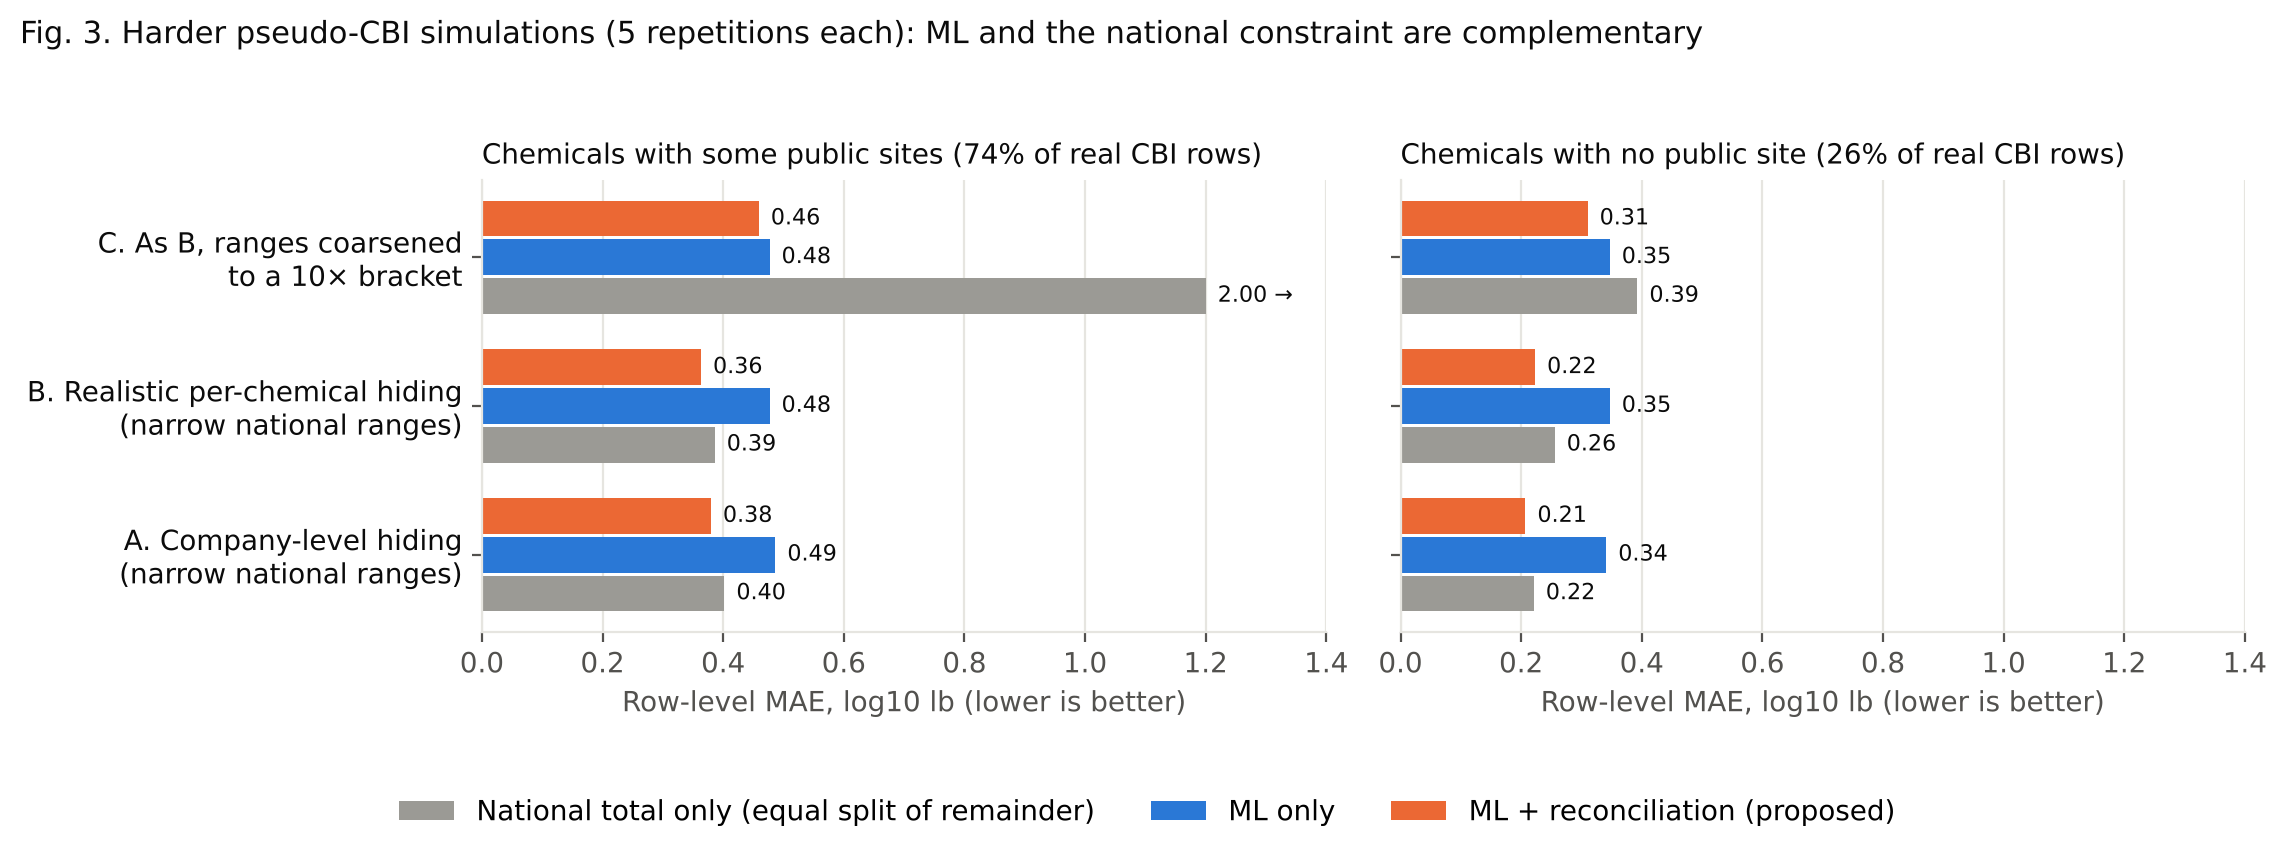

In [12]:
import pandas as pd, numpy as np, matplotlib, sys
matplotlib.use('Agg'); import matplotlib.pyplot as plt
S = pd.read_csv(OUT + '/results_hard_sim_summary.csv')
BLUE, ORANGE, GRAY, AQUA, TXT, TXT2, GRID = '#2a78d6', '#eb6834', '#9b9a95', '#1baf7a', '#0b0b0b', '#52514e', '#e6e5e0'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.edgecolor': GRID, 'xtick.color': TXT2, 'ytick.color': TXT2, 'axes.spines.top': False, 'axes.spines.right': False})
M = [('equal_split_remainder', 'National total only (equal split of remainder)', GRAY), ('ML_only', 'ML only', BLUE), ('ML+reconcile_bound', 'ML + reconciliation (proposed)', ORANGE)]
SC = [('A_company', 'A. Company-level hiding\n(narrow national ranges)'), ('B_empirical_fraction', 'B. Realistic per-chemical hiding\n(narrow national ranges)'), ('C_coarse_range', 'C. As B, ranges coarsened\nto a 10× bracket')]
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4), sharey=True)
for k, (sub, title) in enumerate([('chem_partly_hidden', 'Chemicals with some public sites (74% of real CBI rows)'), ('chem_fully_hidden', 'Chemicals with no public site (26% of real CBI rows)')]):
    a = ax[k]
    for j, (sc, _) in enumerate(SC):
        for o, (mt, lab, c) in enumerate(M):
            r = S[(S.scenario == sc) & (S.subset == sub) & (S.method == mt)].iloc[0]
            v, e = r.MAE_mean, r.MAE_std; yy = j + (o - 1) * 0.26
            a.barh(yy, min(v, 1.2), height=0.24, color=c, label=lab if (k == 0 and j == 0) else None)
            a.text(min(v, 1.2) + 0.02, yy, f'{v:.2f}' + (' →' if v > 1.2 else ''), va='center', fontsize=8, color=TXT)
    a.set_yticks(range(3)); a.set_yticklabels([s[1] for s in SC], color=TXT); a.invert_yaxis(); a.set_xlim(0, 1.4)
    a.set_title(title, loc='left', fontsize=10, color=TXT); a.xaxis.grid(True, color=GRID); a.set_axisbelow(True); a.set_xlabel('Row-level MAE, log10 lb (lower is better)', color=TXT2)
h, l = ax[0].get_legend_handles_labels(); fig.legend(h, l, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Fig. 3. Harder pseudo-CBI simulations (5 repetitions each): ML and the national constraint are complementary', x=0.01, ha='left', fontsize=11, color=TXT)
plt.tight_layout(rect=(0, 0.07, 1, 0.94)); plt.savefig(OUT + '/fig3_hard_simulations.png', dpi=200, bbox_inches='tight')

from IPython.display import Image, display; display(Image(os.path.join(OUT,'fig3_hard_simulations.png')))

## Hạn chế và việc cần làm tiếp
- Mô phỏng ở bước 5 có thể lạc quan: mới chỉ giấu ít dòng cho mỗi hóa chất. Cần thêm kịch bản giấu nhiều cơ sở cho cùng một hóa chất.
- Thêm đặc trưng cấu trúc phân tử (RDKit) và giải thích mô hình bằng SHAP; báo cáo độ biến thiên giữa nhiều seed ngẫu nhiên.
- Đối chiếu lại mã CAS của danh sách 20 chất ưu tiên cao của TSCA.
- Thử phép hiệu chỉnh có trọng số theo độ bất định thay vì co giãn đều.